# EN3160 Assignment 2: Fitting and Alignment

**Name:** Gunarathna K. T. M. B. &nbsp;&nbsp; **Index:** 230203G  
**GitHub:** https://github.com/thidaswingunarathna/EN3160-A02

In [1]:
import numpy as np, cv2 as cv
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize

%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'pil_kwargs': {'quality': 88}}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
IMG = 'images/'
def show(ax, im, title=''):
    ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB)); ax.set_title(title); ax.axis('off')

## Question 1: Blob detection with a scale-space Laplacian of Gaussian

A scale-normalised LoG, σ²·(−∇²(G_σ * I)), is computed for 20 log-spaced scales. Local maxima over (y, x, σ) are blob centres, with radius r = √2·σ.

The sunflowers are detected on the channel R − B. It is high for yellow petals and near zero for white clouds and negative for blue sky, so the clouds are not detected as blobs. A small morphological closing fills the dark flower centres so that each flower is one bright disc. Overlapping detections are suppressed, keeping the strongest.

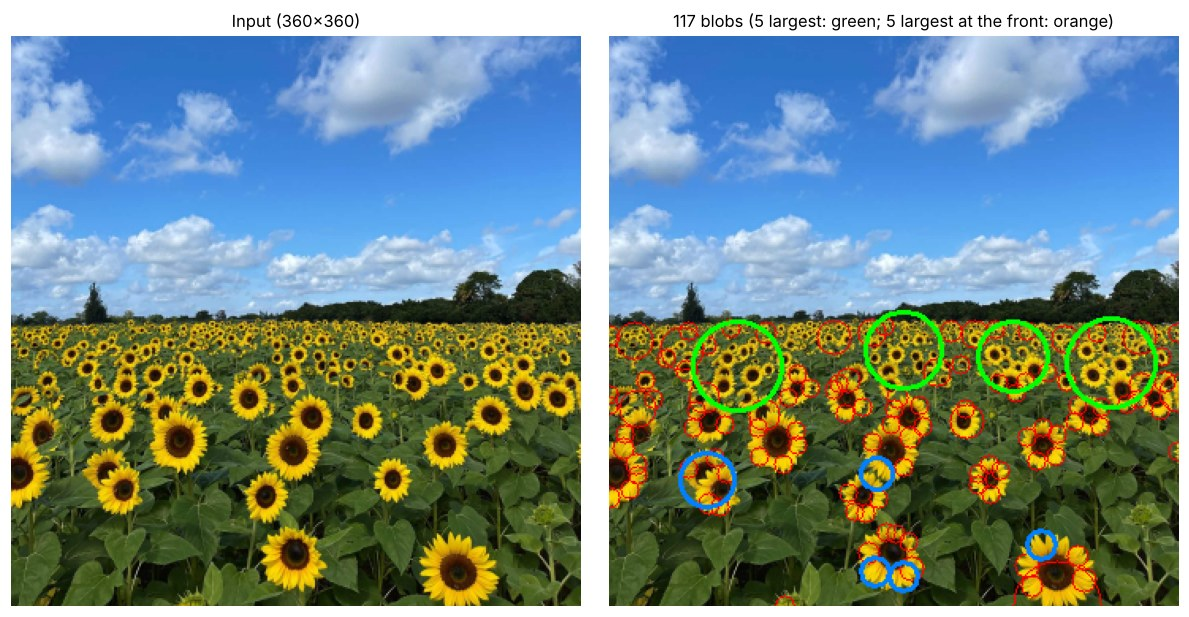

sigma range used: 4.0 to 20.0 (20 levels)  ->  radius range 5.7 to 28.3 px
5 largest circles (not cut by the border)
    x     y   sigma  radius
  317   206   20.00   28.28
   81   208   20.00   28.28
  186   198   16.88   23.88
  255   202   15.51   21.94
   62   280   12.03   17.01
5 largest circles at the front of the field (y > 250)
    x     y   sigma  radius
   62   280   12.03   17.01
  169   276    7.24   10.24
  186   341    6.65    9.40
  168   338    6.65    9.40
  273   321    6.65    9.40


In [2]:
im = cv.imread(IMG + 'the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
b, g, r = [c.astype(np.float64) / 255 for c in cv.split(im)]
chan = np.clip(r - b, 0, 1)
chan = cv.morphologyEx(chan, cv.MORPH_CLOSE, cv.getStructuringElement(cv.MORPH_ELLIPSE, (9, 9)))

SIG_MIN, SIG_MAX, N_SIG, THRESH = 4.0, 20.0, 20, 0.12
sigmas = np.geomspace(SIG_MIN, SIG_MAX, N_SIG)
stack = np.stack([s**2 * (-gaussian_laplace(chan, s)) for s in sigmas], axis=-1)

# strict local maxima in (y, x, sigma)
peaks = (stack == maximum_filter(stack, size=(3, 3, 3))) & (stack > THRESH)
ys, xs, ks = np.nonzero(peaks)
blobs = [(xs[i], ys[i], sigmas[k], np.sqrt(2) * sigmas[k], stack[ys[i], xs[i], k]) for i, k in enumerate(ks)]

# non-maximum suppression: strongest first, drop a blob whose centre lies inside a kept one
kept = []
for bl in sorted(blobs, key=lambda q: -q[4]):
    if all(np.hypot(bl[0] - k[0], bl[1] - k[1]) > 0.7 * max(bl[3], k[3]) for k in kept):
        kept.append(bl)
kept.sort(key=lambda q: -q[3])

out = im.copy()
for x, y, s, rad, v in kept:
    cv.circle(out, (int(x), int(y)), int(round(rad)), (0, 0, 255), 1)
H_, W_ = chan.shape
inside = [q for q in kept if q[0] - q[3] >= 0 and q[0] + q[3] < W_ and q[1] - q[3] >= 0 and q[1] + q[3] < H_]   # not cut by the border
near = [q for q in inside if q[1] > 250]                                                                       # front of the field
for x, y, s, rad, v in inside[:5]:
    cv.circle(out, (int(x), int(y)), int(round(rad)), (0, 255, 0), 2)
for x, y, s, rad, v in near[:5]:
    cv.circle(out, (int(x), int(y)), int(round(rad)), (255, 128, 0), 2)

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
show(ax[0], im, f'Input ({im.shape[1]}x{im.shape[0]})')
show(ax[1], out, f'{len(kept)} blobs (5 largest: green; 5 largest at the front: orange)')
plt.tight_layout(); plt.show()

print(f'sigma range used: {SIG_MIN} to {SIG_MAX} ({N_SIG} levels)  ->  radius range {np.sqrt(2)*SIG_MIN:.1f} to {np.sqrt(2)*SIG_MAX:.1f} px')
for title, lst in (('5 largest circles (not cut by the border)', inside), ('5 largest circles at the front of the field (y > 250)', near)):
    print(title)
    print(f'{"x":>5} {"y":>5} {"sigma":>7} {"radius":>7}')
    for x, y, s, rad, v in lst[:5]:
        print(f'{x:5d} {y:5d} {s:7.2f} {rad:7.2f}')

**Discussion.** The tables list the centre (x, y) in the reduced image, σ and radius r = √2·σ of the largest circles, found with σ in [4, 20] (radii 5.7 to 28.3 px). The five largest circles (green) lie on groups of distant flowers, which merge into one bright blob at a coarse scale, and two of them sit at the upper end of the σ range. At the front of the field (orange) the largest circles are about 10 to 17 px in radius: single large flowers respond most strongly at the scale of their petals (σ ≈ 4 to 7), so they are often covered by several small circles, and the radius-17 circle covers two touching flowers. Blobs cut by the image border have an underestimated radius and are left out of the lists.

## Question 2: RANSAC line and circle fitting

The point set is generated as in the assignment listing (50 circle points, centre (2, 3), r = 10, radial noise σ = r/16; 50 line points on y = −x + 2 with σ = 1).

**Models.** Line: ax + by = d with ‖[a, b]‖ = 1 (error = |ax + by − d|). Circle: centre (x₀, y₀), radius r (error = | ‖p − c‖ − r |).

**Parameters.** Line threshold 1.5 (about 2× the normal-distance noise, σ ≈ 0.7), consensus ≥ 40 of the 50 line points. Circle threshold 1.25 (about 2× the radial noise 0.625), consensus ≥ 35 of the roughly 50 remaining points. Each best sample is refined on its inliers with `scipy.optimize.minimize`; the line uses an explicit constraint a² + b² = 1.

In [3]:
def make_data(rng, N=100, r=10, c=(2, 3), m=-1, b0=2):
    h = N // 2
    t = rng.uniform(0, 2 * np.pi, h); n = (r / 16) * rng.standard_normal(h)
    Xc = np.c_[c[0] + (r + n) * np.cos(t), c[1] + (r + n) * np.sin(t)]
    x = np.linspace(-12, 12, h); y = m * x + b0 + 1.0 * rng.standard_normal(h)
    return np.vstack([Xc, np.c_[x, y]])

# ---------- line model
def line_from_2pts(p, q):
    d = q - p; n = np.hypot(*d)
    a, b = -d[1] / n, d[0] / n                      # unit normal
    return np.array([a, b, a * p[0] + b * p[1]])
def line_err(X, L): return np.abs(X @ L[:2] - L[2])

def refine_line(X, L0):
    cost = lambda L: np.sum((X @ L[:2] - L[2])**2)
    con = {'type': 'eq', 'fun': lambda L: L[0]**2 + L[1]**2 - 1}
    return minimize(cost, L0, constraints=[con], method='SLSQP').x

# ---------- circle model
def circle_from_3pts(P):
    A = 2 * np.c_[P[1] - P[0], P[2] - P[0]].T
    if abs(np.linalg.det(A)) < 1e-9: return None
    rhs = np.array([P[1] @ P[1] - P[0] @ P[0], P[2] @ P[2] - P[0] @ P[0]])
    c = np.linalg.solve(A, rhs)
    return np.array([c[0], c[1], np.hypot(*(P[0] - c))])
def circ_err(X, M): return np.abs(np.hypot(X[:, 0] - M[0], X[:, 1] - M[1]) - M[2])

def refine_circle(X, M0):
    cost = lambda M: np.sum((np.hypot(X[:, 0] - M[0], X[:, 1] - M[1]) - M[2])**2)
    return minimize(cost, M0, method='BFGS').x

# ---------- generic RANSAC (returns best sample, its model, inlier mask)
def ransac(X, k, fit, err, thr, min_inl, iters, rng):
    best = None
    for _ in range(iters):
        idx = rng.choice(len(X), k, replace=False)
        M = fit(*[X[i] for i in idx]) if k == 2 else fit(X[idx])
        if M is None: continue
        inl = err(X, M) < thr
        if inl.sum() >= min_inl and (best is None or inl.sum() > best[2].sum()):
            best = (idx, M, inl)
    return best

LINE_THR, LINE_MIN, LINE_IT = 1.5, 40, 300
CIRC_THR, CIRC_MIN, CIRC_IT = 1.25, 35, 1000

### (a), (b), (c) Line first, then circle on the remainder

Line   : a=0.714 b=0.700 d=1.553   inliers=52   (ground truth y=-x+2: a=0.707 b=0.707 d=1.414)
Circle : centre=(1.960,2.964) r=9.889   inliers=45   (ground truth centre=(2,3) r=10)
Remnant after line removal: 48 points


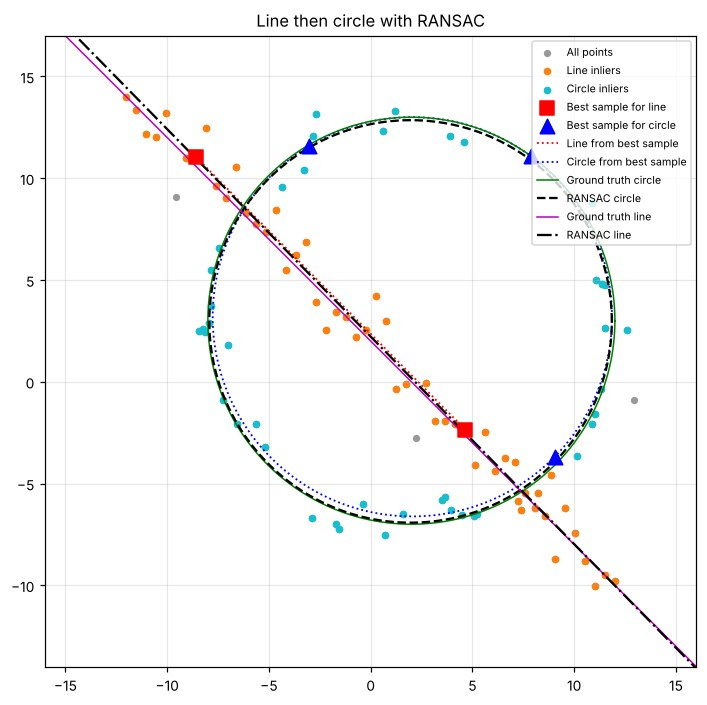

In [4]:
rng = np.random.default_rng(3160)
X = make_data(rng)

# (a) line
idxL, ML, inL = ransac(X, 2, line_from_2pts, line_err, LINE_THR, LINE_MIN, LINE_IT, rng)
L = refine_line(X[inL], ML)
if L[2] < 0: L = -L
# (b) circle on the remnant
Xr = X[~inL]
idxC, MC, inC = ransac(Xr, 3, lambda P: circle_from_3pts(P), circ_err, CIRC_THR, CIRC_MIN, CIRC_IT, rng)
C = refine_circle(Xr[inC], MC)

print(f'Line   : a={L[0]:.3f} b={L[1]:.3f} d={L[2]:.3f}   inliers={inL.sum()}   (ground truth y=-x+2: a=0.707 b=0.707 d=1.414)')
print(f'Circle : centre=({C[0]:.3f},{C[1]:.3f}) r={C[2]:.3f}   inliers={inC.sum()}   (ground truth centre=(2,3) r=10)')
print(f'Remnant after line removal: {len(Xr)} points')

# (c) plot
fig, ax = plt.subplots(figsize=(6.5, 6.5))
th = np.linspace(0, 2 * np.pi, 400)
ax.scatter(*X.T, s=14, c='0.6', label='All points')
ax.scatter(*X[inL].T, s=16, c='tab:orange', label='Line inliers')
ax.scatter(*Xr[inC].T, s=16, c='tab:cyan', label='Circle inliers')
ax.scatter(*X[idxL].T, s=90, marker='s', c='r', label='Best sample for line', zorder=5)
ax.scatter(*Xr[idxC].T, s=90, marker='^', c='b', label='Best sample for circle', zorder=5)
xs_ = np.array([-16, 16.])
pL = X[idxL]; ax.plot(pL[:, 0], pL[:, 1], 'r:', lw=1.2, label='Line from best sample')
ax.plot(MC[0] + MC[2] * np.cos(th), MC[1] + MC[2] * np.sin(th), 'b:', lw=1.2, label='Circle from best sample')
ax.plot(2 + 10 * np.cos(th), 3 + 10 * np.sin(th), 'g-', lw=1, label='Ground truth circle')
ax.plot(C[0] + C[2] * np.cos(th), C[1] + C[2] * np.sin(th), 'k--', lw=1.5, label='RANSAC circle')
ax.plot(xs_, -xs_ + 2, 'm-', lw=1, label='Ground truth line')
ax.plot(xs_, (L[2] - L[0] * xs_) / L[1], 'k-.', lw=1.5, label='RANSAC line')
ax.set_xlim(-16, 16); ax.set_ylim(-14, 17); ax.set_aspect('equal'); ax.grid(alpha=.3)
ax.legend(fontsize=7, loc='upper right', ncol=1); ax.set_title('Line then circle with RANSAC')
plt.tight_layout(); plt.show()

### (d) What if the circle is fitted first?

Circle first: centre=(2.11,2.84) r=10.09  inliers=54  (ground truth centre=(2,3) r=10)
Of its inliers: 47 are true circle points, 7 are line points


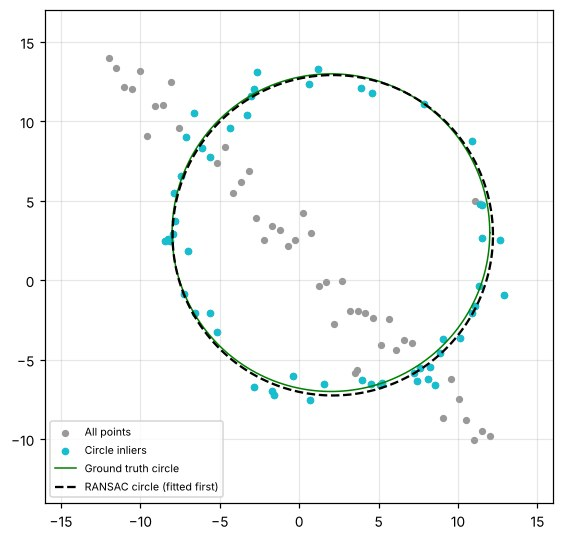

line first  : correct circle in 100/100 random point sets


circle first: correct circle in 91/100 random point sets; wrong fits have radius 161 to 7345 (true r = 10)


In [5]:
rng = np.random.default_rng(3160)
X = make_data(rng)
idxC1, MC1, inC1 = ransac(X, 3, lambda P: circle_from_3pts(P), circ_err, CIRC_THR, CIRC_MIN, CIRC_IT, rng)
Cf = refine_circle(X[inC1], MC1)
print(f'Circle first: centre=({Cf[0]:.2f},{Cf[1]:.2f}) r={Cf[2]:.2f}  inliers={inC1.sum()}  (ground truth centre=(2,3) r=10)')
print(f'Of its inliers: {inC1[:50].sum()} are true circle points, {inC1[50:].sum()} are line points')

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(*X.T, s=14, c='0.6', label='All points'); ax.scatter(*X[inC1].T, s=16, c='tab:cyan', label='Circle inliers')
ax.plot(2 + 10 * np.cos(th), 3 + 10 * np.sin(th), 'g-', lw=1, label='Ground truth circle')
ax.plot(Cf[0] + Cf[2] * np.cos(th), Cf[1] + Cf[2] * np.sin(th), 'k--', lw=1.5, label='RANSAC circle (fitted first)')
ax.set_xlim(-16, 16); ax.set_ylim(-14, 17); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# repeat over many random point sets: line-first vs circle-first
def trial(seed, circle_first):
    rg = np.random.default_rng(seed); Xs = make_data(rg)
    if circle_first:
        res = ransac(Xs, 3, lambda P: circle_from_3pts(P), circ_err, CIRC_THR, CIRC_MIN, CIRC_IT, rg)
    else:
        _, _, inl = ransac(Xs, 2, line_from_2pts, line_err, LINE_THR, LINE_MIN, LINE_IT, rg)
        res = ransac(Xs[~inl], 3, lambda P: circle_from_3pts(P), circ_err, CIRC_THR, CIRC_MIN, CIRC_IT, rg)
    if res is None: return False, np.nan
    Mc = refine_circle((Xs if circle_first else Xs[~inl])[res[2]], res[1])
    ok = np.hypot(Mc[0] - 2, Mc[1] - 3) < 1 and abs(Mc[2] - 10) < 1
    return ok, Mc[2]
for cf in (False, True):
    R = [trial(s, cf) for s in range(100)]
    bad = [rad for ok, rad in R if not ok]
    msg = f'{"circle first" if cf else "line first  "}: correct circle in {sum(o for o, _ in R)}/100 random point sets'
    if bad: msg += f'; wrong fits have radius {min(bad):.0f} to {max(bad):.0f} (true r = 10)'
    print(msg)

**Discussion.** With the line removed first, the remaining points are almost all circle points, and the circle RANSAC succeeds in every trial. When the circle is fitted first, the 50 line points are outliers for it, and a circle of very large radius through three line points is almost a straight segment that also collects about 50 inliers (the line points plus a few circle points near it). Its consensus can exceed that of the true circle, and the repeat trials show that this is the failure that occurs: the wrong fits are huge circles lying along the line. The line-first order is more reliable because a straight line cannot be imitated by a bounded-radius circle, while a circle of large radius can imitate a line. A cap on the radius, or a consensus score that prefers small radius, would also help when fitting the circle first.

## Question 3: Homography and superimposing images

Four corners of a planar surface are chosen in the target image (fixed coordinates, ordered TL, TR, BR, BL). The homography is computed from the four source-to-target corner correspondences, the source is warped with it and alpha-blended onto the target.

**Choice of pairs.** (1) The UK flag on the plain wall of the chapel wing of Wadham College, as a flag hung on a college building. (2) A sunflower field on the long wall of the other wing, a bright banner against the dull stone, which makes the blend easy to judge.

UK flag on the chapel wing wall 
H =
 [[ 6.81e-02  0.00e+00  7.00e+02]
 [-4.24e-02  1.46e-01  3.80e+02]
 [-1.00e-04  0.00e+00  1.00e+00]]
Sunflowers on the long wing wall 
H =
 [[3.797e-01 0.000e+00 1.500e+02]
 [1.420e-01 2.712e-01 3.250e+02]
 [3.000e-04 0.000e+00 1.000e+00]]


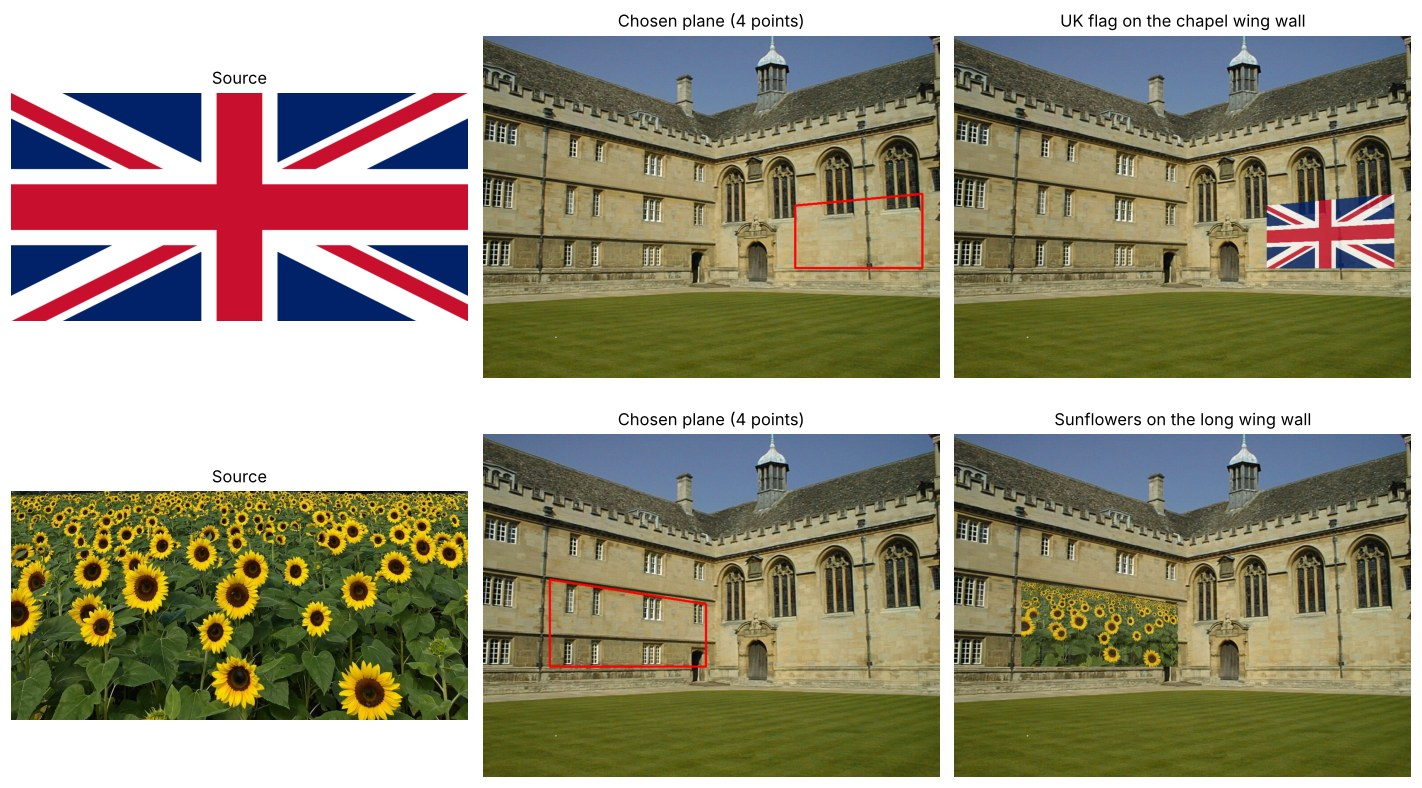

In [6]:
def superimpose(target, source, quad, alpha=0.8):
    h, w = source.shape[:2]
    src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    H = cv.getPerspectiveTransform(src, np.float32(quad))
    size = (target.shape[1], target.shape[0])
    warped = cv.warpPerspective(source, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0
    out = target.copy()
    out[mask] = (alpha * warped[mask] + (1 - alpha) * target[mask]).astype(np.uint8)
    return out, H

wad  = cv.imread(IMG + 'wadham.jpg')
flag = cv.imread(IMG + 'flag.png')
sun  = cv.imread(IMG + 'the_berry_farms_sunflower_field.jpeg')[720:, :]   # lower half of the field, 2:1 like the wall patch

pairs = [('UK flag on the chapel wing wall', flag, [(700, 380), (985, 354), (985, 520), (700, 520)]),
         ('Sunflowers on the long wing wall',  sun,  [(150, 325), (500, 380), (500, 520), (150, 520)])]

fig, ax = plt.subplots(2, 3, figsize=(13, 7.6))
for row, (name, src, quad) in zip(ax, pairs):
    res, H = superimpose(wad, src, quad)
    marked = wad.copy(); cv.polylines(marked, [np.int32(quad)], True, (0, 0, 255), 3)
    show(row[0], src, 'Source'); show(row[1], marked, 'Chosen plane (4 points)'); show(row[2], res, name)
    print(name, '\nH =\n', np.round(H / H[2, 2], 4))
plt.tight_layout(); plt.show()

**Discussion.** Both overlays follow the perspective of their wall, with the lines of the flag and the banner converging in the same way as the building's lines. The match is good because the chosen quadrilaterals lie on the wall plane and their corners follow the wall's vanishing lines. The corners were picked by eye, so small errors of a few pixels show up as slight skew at the edges, and alpha blending keeps the stone texture and the windows visible through the overlay.

## Question 4: PCB alignment with SIFT and RANSAC homography

Images are downscaled by 2 for speed. SIFT features are matched with `cv2.BFMatcher` (k-NN, Lowe ratio test 0.8), the homography is estimated with RANSAC (reprojection threshold 3 px) and each image is warped into the template frame (`AECC1.jpg`). The difference image is the absolute grey-level difference between the warped image and the template.

In [7]:
S = 0.5
def load(name): return cv.resize(cv.imread(IMG + 'pcbs/' + name), None, fx=S, fy=S, interpolation=cv.INTER_AREA)
sift = cv.SIFT_create()
T = load('AECC1.jpg'); Tg = cv.cvtColor(T, cv.COLOR_BGR2GRAY)
kt, dt = sift.detectAndCompute(Tg, None)

def align(name, ratio=0.8):
    I = load(name); Ig = cv.cvtColor(I, cv.COLOR_BGR2GRAY)
    ki, di = sift.detectAndCompute(Ig, None)
    knn = cv.BFMatcher().knnMatch(di, dt, k=2)
    good = [m for m, n in knn if m.distance < ratio * n.distance]
    src = np.float32([ki[m.queryIdx].pt for m in good]); dst = np.float32([kt[m.trainIdx].pt for m in good])
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 3.0)
    mask = mask.ravel().astype(bool)
    W = cv.warpPerspective(I, H, (T.shape[1], T.shape[0]))
    valid = cv.warpPerspective(np.full(Ig.shape, 255, np.uint8), H, (T.shape[1], T.shape[0])) > 0
    diff = cv.absdiff(cv.cvtColor(W, cv.COLOR_BGR2GRAY), Tg)
    sel = [m for m, k in zip(good, mask) if k]
    sel = [sel[i] for i in np.linspace(0, len(sel) - 1, min(60, len(sel))).astype(int)]   # 60 matches for readability
    vis = cv.drawMatches(I, ki, T, kt, sel, None, matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return dict(name=name, nkp=len(ki), ngood=len(good), ninl=int(mask.sum()), W=W, diff=diff, vis=vis, mean=diff[valid].mean())

names = ['AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg', 'AAAA1.jpg', 'ADAD1.jpg']
results = [align(n) for n in names]

print(f'Template AECC1.jpg: {len(kt)} SIFT keypoints')
print(f'{"image":10} {"keypoints":>9} {"good matches":>13} {"RANSAC inliers":>15} {"mean |diff|":>12}')
for r_ in results: print(f'{r_["name"]:10} {r_["nkp"]:9d} {r_["ngood"]:13d} {r_["ninl"]:15d} {r_["mean"]:12.1f}')

Template AECC1.jpg: 6991 SIFT keypoints
image      keypoints  good matches  RANSAC inliers  mean |diff|
AECC2.jpg       6923          3454            3000          2.7
AECC3.jpg       6720          3948            3478          2.4
AECC4.jpg       7205          3561            3051          3.4
AAAA1.jpg       1431            76              28         28.2
ADAD1.jpg       5449           414             241         31.1


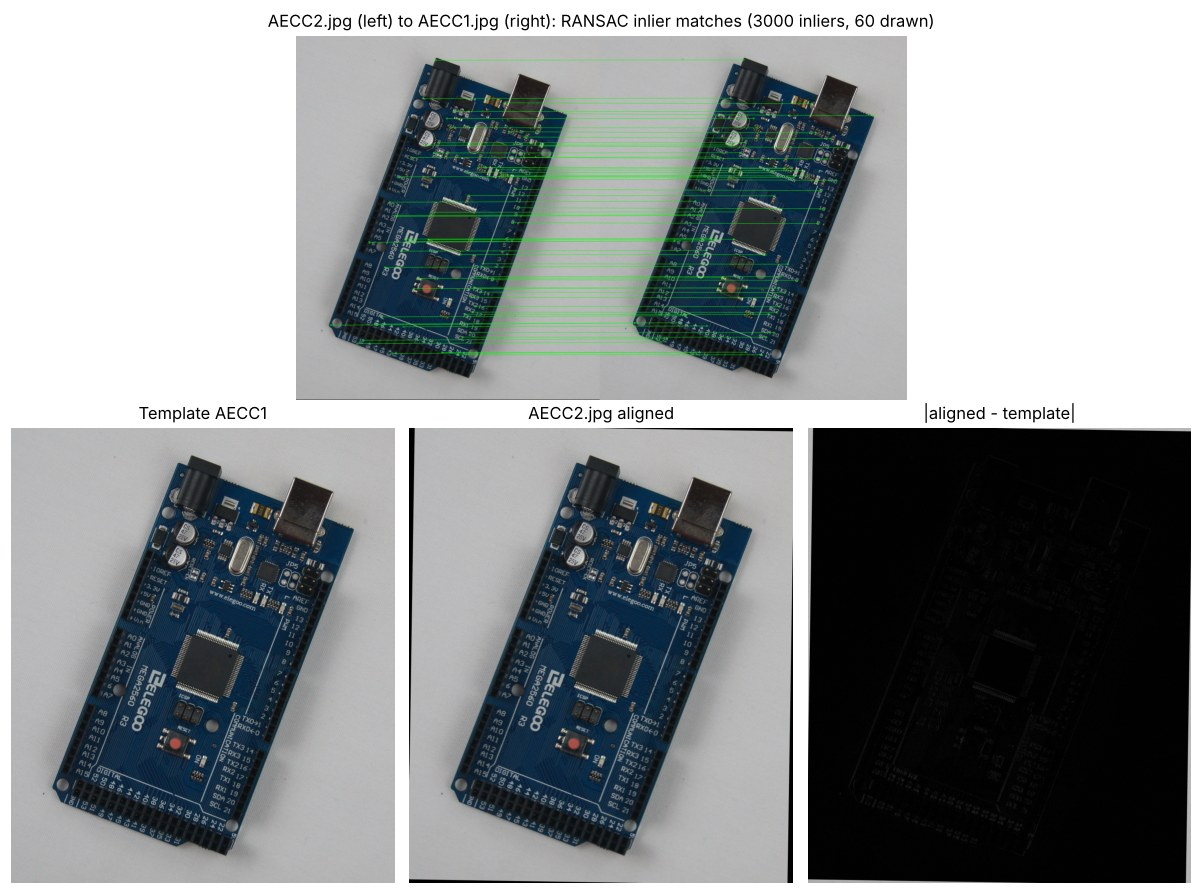

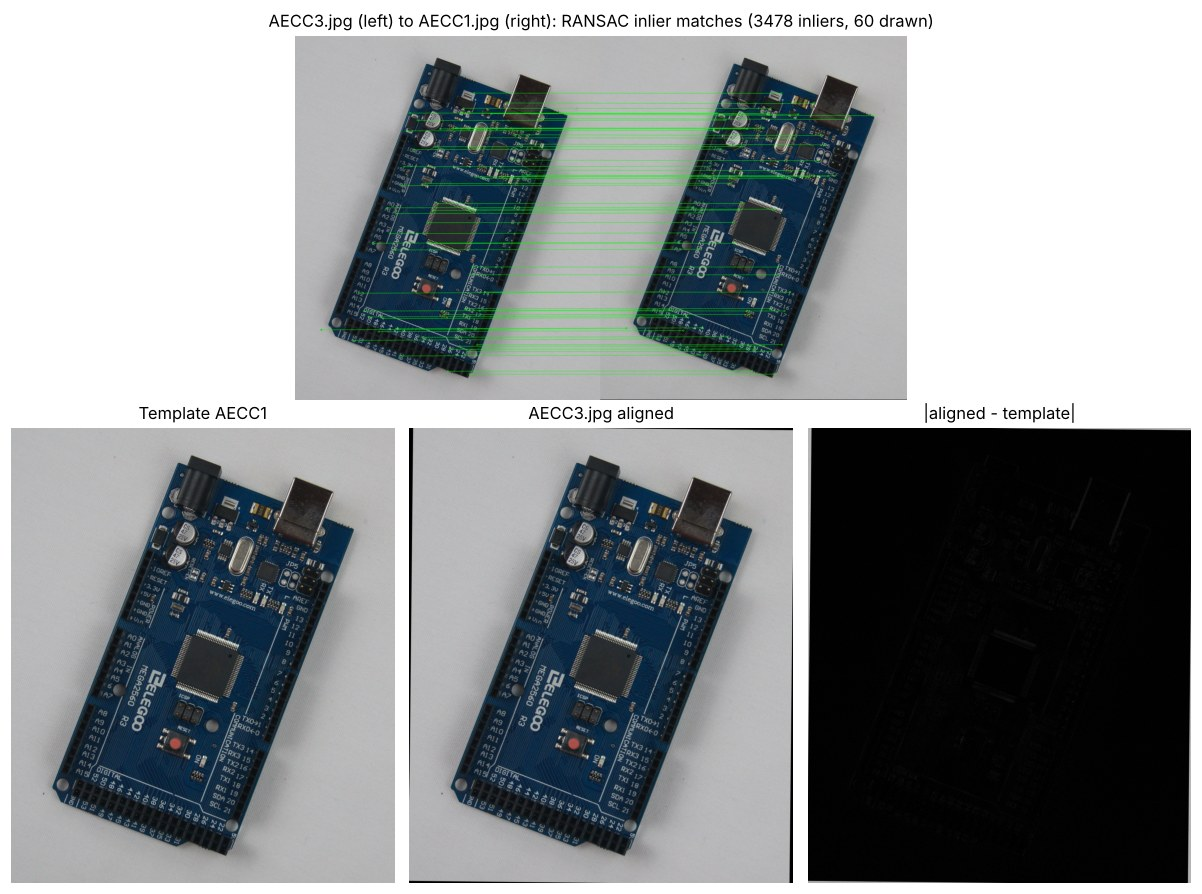

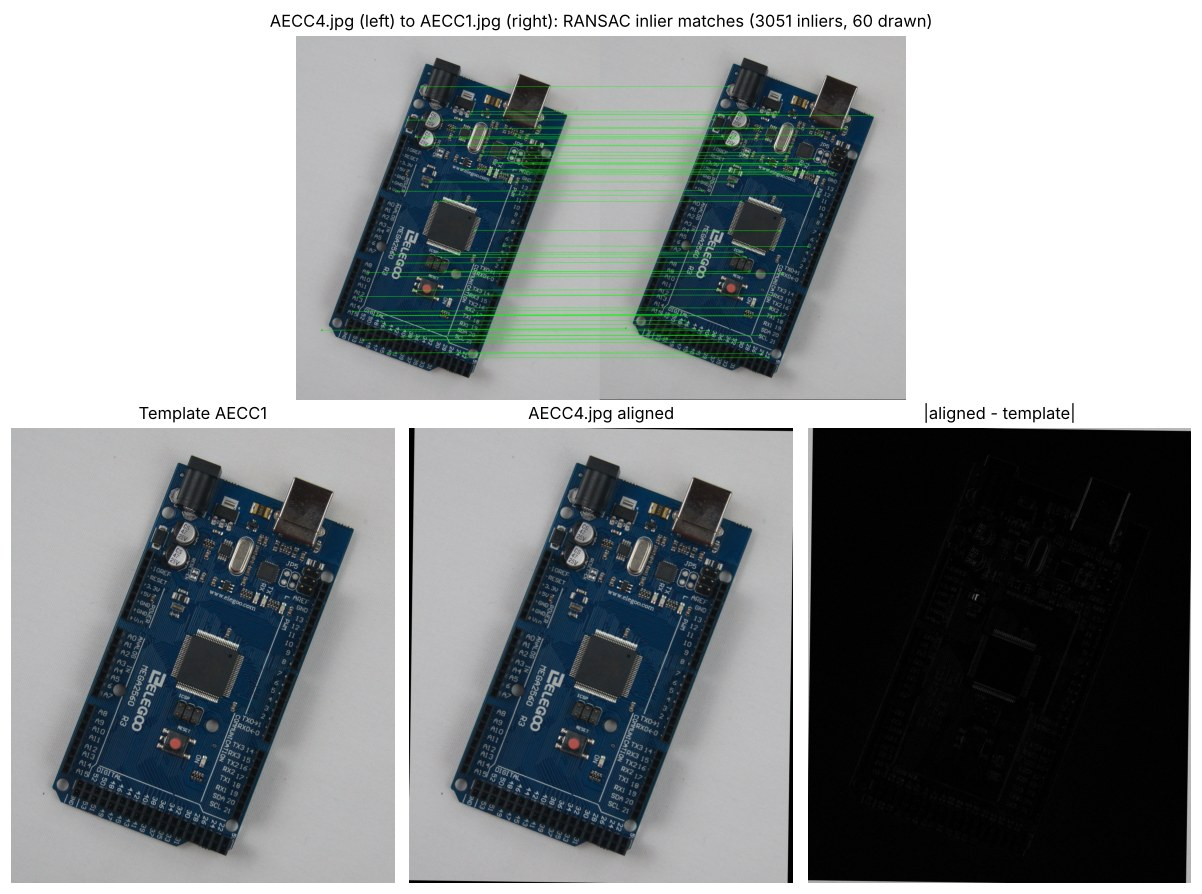

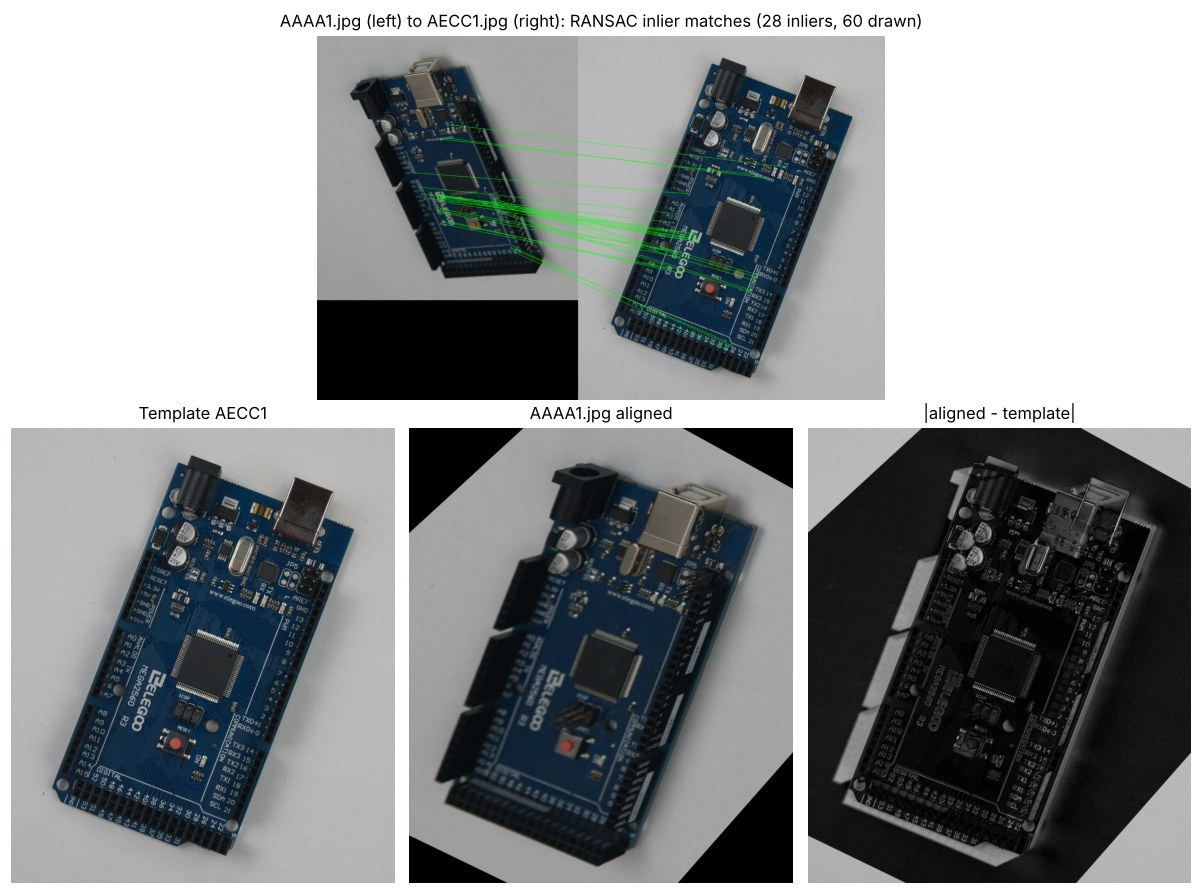

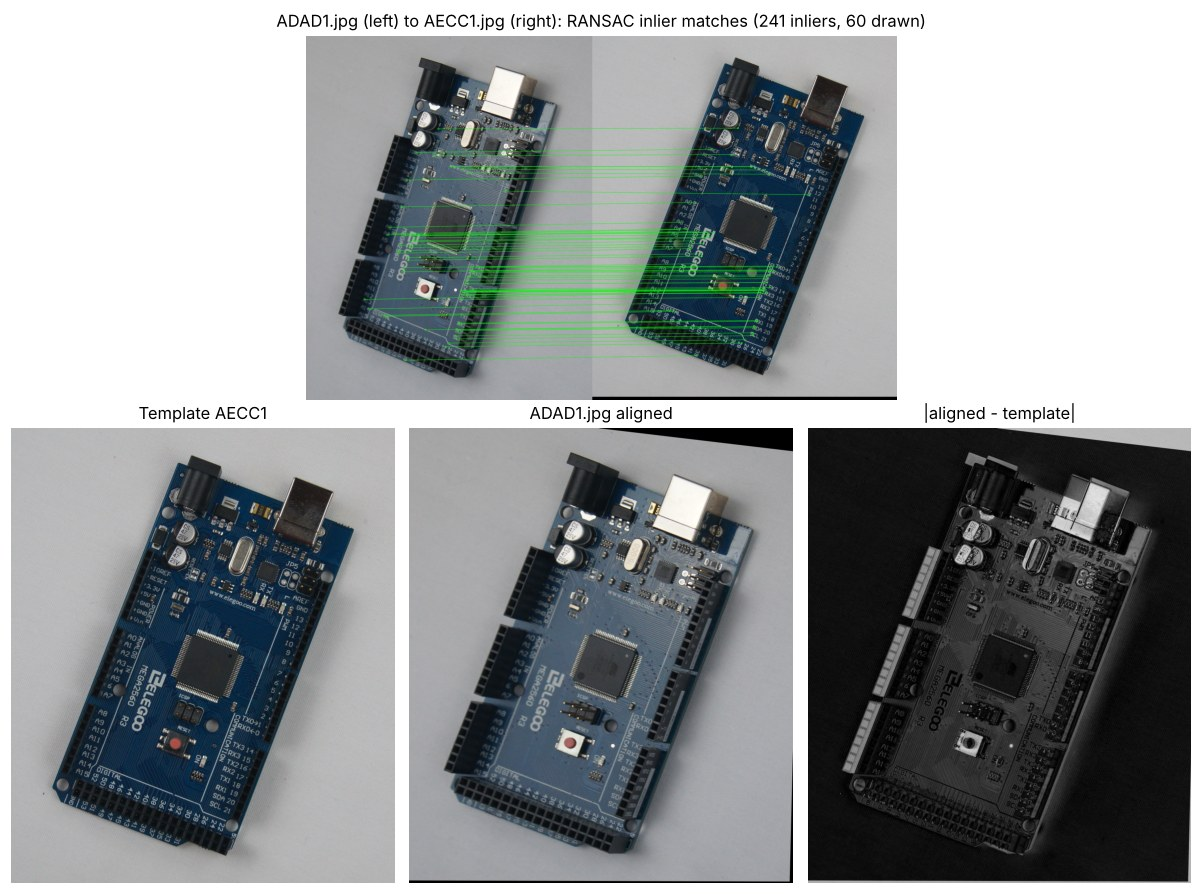

In [8]:
for r_ in results:
    fig = plt.figure(figsize=(11, 8.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.25])
    a = fig.add_subplot(gs[0, :]); show(a, r_['vis'], f'{r_["name"]} (left) to AECC1.jpg (right): RANSAC inlier matches ({r_["ninl"]} inliers, 60 drawn)')
    show(fig.add_subplot(gs[1, 0]), T, 'Template AECC1')
    show(fig.add_subplot(gs[1, 1]), r_['W'], f'{r_["name"]} aligned')
    d = fig.add_subplot(gs[1, 2]); d.imshow(r_['diff'], cmap='gray', vmin=0, vmax=255); d.set_title('|aligned - template|'); d.axis('off')
    plt.tight_layout(); plt.show()

### (d) Summary of difference images

All five warped images are shown above with their difference images; the table gives the number of inliers and the mean absolute difference over the warped board region.

### (e) Why do the USB port, capacitors and the reset button show a large difference?

The homography is exact only for points on one plane (the board surface). The USB port, capacitors and crystal are tall components, so for a different camera position they appear shifted relative to the board, and warping cannot undo this parallax (it is strongest for AAAA1, which is photographed at the largest tilt). The USB shell and the capacitor tops are also shiny metal, so their brightness changes with the viewing angle and lighting. The reset button changes colour and brightness between photographs (visibly lighter in ADAD1). Small residual misregistration and blur from the strong warp of AAAA1 and the difference in board colour and exposure in ADAD1 raise the difference over the whole board, which is why their mean difference is about ten times larger than for AECC2 to AECC4.